In [110]:
import numpy as np
import seaborn as sns
from scipy.signal import correlate2d
from Cell2D import Cell2D, draw_array
from matplotlib.colors import LinearSegmentedColormap
from scipy.signal import correlate2d
from empiricaldist import Cdf
from utils import three_frame, number_frame, decorate, set_palette
import matplotlib.pyplot as plt

In [111]:
# make a custom color map
palette = sns.color_palette('muted')
colors = 'white', palette[1], palette[0]
cmap = LinearSegmentedColormap.from_list('cmap', colors)

#考虑到后面还需要结婚搬家之类的，参考一下老师的sugar模型，地图（房子）和agent单独做一个class

In [112]:
class Person():

    id = 0

    def __init__(self, loc, group):
        """
        group:
            1 = red / group A
            2 = blue / group B
        """

        # 给每个人一个独立 ID
        # 后面记录组合，和谁呆了一起，就很方便记录
        self.id = Person.id
        Person.id += 1

        # 当前住的位置
        self.loc = tuple(loc)

        # 保存这个人的原始 group
        self.group = group

        # 每个人独立随机一个 openness
        # 0.1, 0.2, ..., 0.9
        self.openness = np.random.randint(1, 10) / 10

In [113]:
def locs_where(condition):
    """Find cells where a logical array is True.

    condition: logical array

    returns: list of location tuples (identified by the row/column indices)
    """
    return list(zip(*np.nonzero(condition)))

class Schelling(Cell2D):
    """Represents a grid of Schelling agents."""

    options = dict(mode='same', boundary='wrap')

    kernel = np.array([[1, 1, 1],
                       [1, 0, 1],
                       [1, 1, 1]], dtype=np.int8)

    def __init__(self, n, p):
        """Initializes the attributes.

        n: number of rows -- size of the grid
        p: threshold on the fraction of similar neighbors 满意度阈值
        """
        self.p = p
        # 0 is empty house, 1 is agent labelled red, 2 is agent labelled blue
        choices = np.array([0, 1, 2], dtype=np.int8)
        probs = [0.1, 0.45, 0.45]

        # randomly initialize a grid of houses of n by, occupied by two kinds of agents (red and blue)
        # in roughly equal numbers. About 10% of the houses are empty.
        # in [0, 1, 2], o has 10% to be chosen, 1 and 2 each has 45% to be chosen.
        self.array = np.random.choice(choices, (n, n), p=probs) # 这句已经随机生成了 0 / 1 / 2

        #我得知道上一个代码以及随机生成了0，1，2空房子的不同的group，现在得把每个人信息收集起来
        # Dictionary: key = location, for example (3, 5) value = Person object
        # empty cells will NOT be stored here

        self.people = {}

        # 遍历整个 grid，得到所有的person
        for row in range(n):
            for col in range(n):
                group = self.array[row, col] #一共就只有0，1，2
                # 0 是空房，所以不创建 Person
                if group != 0:
                    loc = (row, col) # 创建这个位置上的 Person
                    person = Person(loc, group)
                    self.people[loc] = person # 保存 Person


    def count_neighbors(self):
        """Surveys neighboring cells.

        returns: tuple of
            empty: True where cells are empty
            frac_red: fraction of red neighbors around each cell
            frac_blue: fraction of blue neighbors around each cell
            frac_same: fraction of neighbors with the same color
        """
        a = self.array

        # create three arrays that contain False/True (0/1) values
        # to later count the different type of neighbours separately
        empty = a==0
        red = a==1 #先把red和blue单独摘出来方便后面计算每个agent分别有多少个red和blue
        blue = a==2

        # correlate with the kernel, considering the 8 surronding neighbours
        # for agent labelled by red, count how many neighbours are also red agents
        # for agent labelled by blue, count how many neigbours are also blue neighbours
        num_red = correlate2d(red, self.kernel, **self.options)
        num_blue = correlate2d(blue, self.kernel, **self.options)
        
        # for each aget, count the total neighbours (no matter blue or red) it has
        num_neighbors = num_red + num_blue

        # compute fraction of similar neighbors 分别计算red和blue的领居占比
        # Some cells may have no occupied neighbours, so num_neighbors can be 0.
        # Ignore the temporary division warning here.
        with np.errstate(divide='ignore', invalid='ignore'):
            frac_red = num_red / num_neighbors 
            frac_blue = num_blue / num_neighbors

        # no neighbors is considered the same as no similar neighbors 如果周围领居的数为0，就把red和blue的设为0
        # (this is an arbitrary choice for a rare event)

        frac_red[num_neighbors == 0] = 0
        frac_blue[num_neighbors == 0] = 0

        # for each cell, fill the fraction of neighbors with the same color
        # wherever red is True, frac_same gets the corresponding element of frac_red.
        # where red is False, frac_same gets the corresponding element of frac_blue.
        # np.where(condition, value_if_true, value_if_false) 如果这个位置是 red，就用 frac_red；否则用 frac_blue。
        frac_same = np.where(red, frac_red, frac_blue)

        # where red is False could be either blue or empty
        # thus, one additional step:
        # for empty cells, frac_same is NaN
        # 如果是空房子，单独设置一下
        frac_same[empty] = np.nan

        # 先复制原来的 frac_same，保持相同的 grid 大小
        satisfaction = frac_same.copy()
        # 每个人使用自己的 openness 计算 satisfaction
        for loc, person in self.people.items():
            satisfaction[loc] = (frac_same[loc]+ (1 - frac_same[loc]) * person.openness)

        # 如果周围一个邻居都没有，不应该因为 openness 很高就得到很高的 satisfaction。
        # 所以我们仍然按照原模型的思路：no neighbours -> satisfaction = 0
        satisfaction[num_neighbors == 0] = 0

        # 同样的空房子不存在 agent，所以没有satisfaction
        satisfaction[empty] = np.nan

        return empty, frac_red, frac_blue, frac_same, satisfaction

    def segregation(self):
        """Computes the average fraction of similar neighbors.
        returns: fraction of similar neighbors, averaged over cells
        segregation 的含义，如果返回：0.72
        意思：平均而言，每个 agent 的邻居中约 72% 和自己同类型。
        """
        # For quantitative analysis of segregation
        _, _, _, frac_same, _ = self.count_neighbors()
        return np.nanmean(frac_same)

    def step(self):
        """Executes one time step.
        returns: fraction of similar neighbors, averaged over cells
        """
        a = self.array
        empty, _, _, frac_same, satisfaction = self.count_neighbors()

        # find the unhappy cells (ignore NaN in frac_same)
        with np.errstate(invalid='ignore'):
            unhappy = satisfaction < self.p # an agent will be unhappy if fewer than p of their neighbors are the same color.
        unhappy_locs = locs_where(unhappy) # return list of (row, column) index tuples to specify the unhappy location

        # find the empty cells: the list of (row, column) index tuples for empty location
        empty_locs = locs_where(empty)

        # shuffle the unhappy cells
        #因为不希望：永远按照 row 0 → row 1 → row 2 的固定顺序搬家。这样模型会产生人为的方向性 bias。随机 shuffle 更合理
        if len(unhappy_locs):
            np.random.shuffle(unhappy_locs)

        # for each unhappy cell, choose a random destination
        num_empty = np.sum(empty)

        for source in unhappy_locs:
            i = np.random.randint(num_empty) #随机得到一个空房子
            dest = empty_locs[i] #准备搬到这个空房子

            # 找到 source 上的 Person
            # 同时删除旧 location 的 dictionary 记录
            # pop 从字典里“取出这个值，并且把这一项删除”
            person = self.people.pop(source)

            # move
            a[dest] = person.group # unhappy agent moves to the empty location, state value updates from 0 to 1 or 2 人先过去
            a[source] = 0 # the unhappy agent's location becomes empty after it moves away 老房子没人了
            person.loc = tuple(dest) # update person's location in class

            self.people[dest] = person # 更新当前class中的people字典
            empty_locs[i] = source # update the empty location list to include the location of unhappy agent that just moved away 把老房子加入空房子列表

            # check that the number of empty cells remains the same
            num_empty2 = np.sum(a==0)
            assert num_empty == num_empty2

        # return the average fraction of similar neighbors
        return np.nanmean(frac_same)

    def draw(self):
        """Draws the cells."""
        return draw_array(self.array, cmap=cmap, vmax=2)

接下来就是住房的问题，后面如果出现结婚或则组合的情况，那么这个这个房子对附近邻居产生的影响是根据这个房子里住的人住了哪些人

In [114]:
grid = Schelling(n=100, p=0.4)

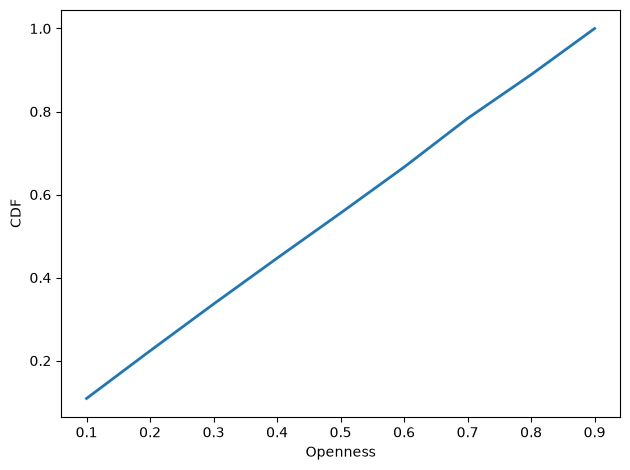

In [115]:
# Check the initial distribution of openness
cdf = Cdf.from_seq(
    person.openness
    for person in grid.people.values()
)

cdf.plot()

decorate(
    xlabel='Openness',
    ylabel='CDF'
)

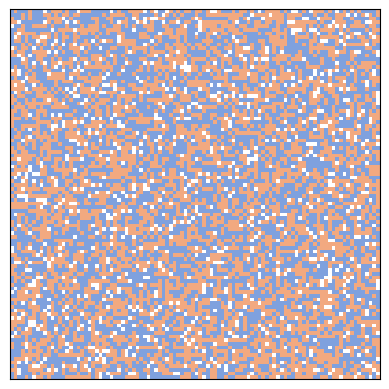

In [116]:
grid.draw()

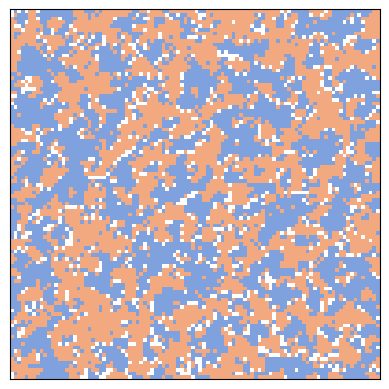

In [117]:
grid = Schelling(n=100, p=0.76)
grid.animate(frames=10, interval=0.1) #animate这个function里面有step会自己跳动

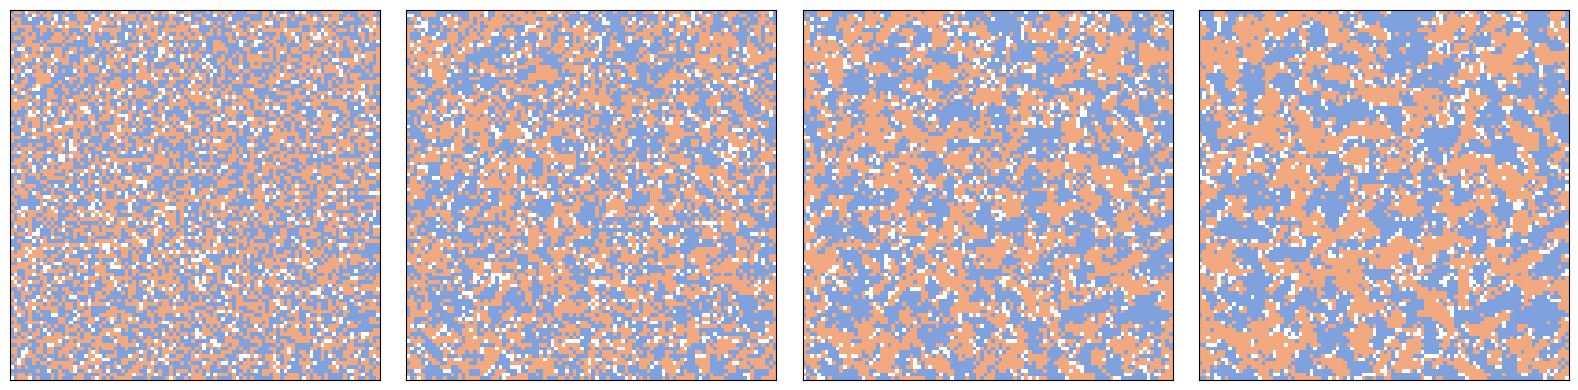

In [118]:
grid = Schelling(n=100, p=0.76)
# three_frame(grid, [0, 2, 8]) #step0,0+2,0+2+8
number_frame(grid,[0,2,3,5],4)

# 图 1：p=0.2 ～ 0.9的整体趋势
这张图主要用来观察不同满意度阈值p对segregation的整体影响。可以看到，p从0.2增加到0.8时，最终segregation总体上逐渐提高；但当p=0.9时，segregation反而下降，而且曲线持续波动。这说明segregation并不是随着p无限增加，而是在较高p附近达到峰值后开始下降。一个可能原因是，当满意度要求过高时，大量Agent很难找到满足条件的位置，因此不断随机搬家，系统反而难以稳定。

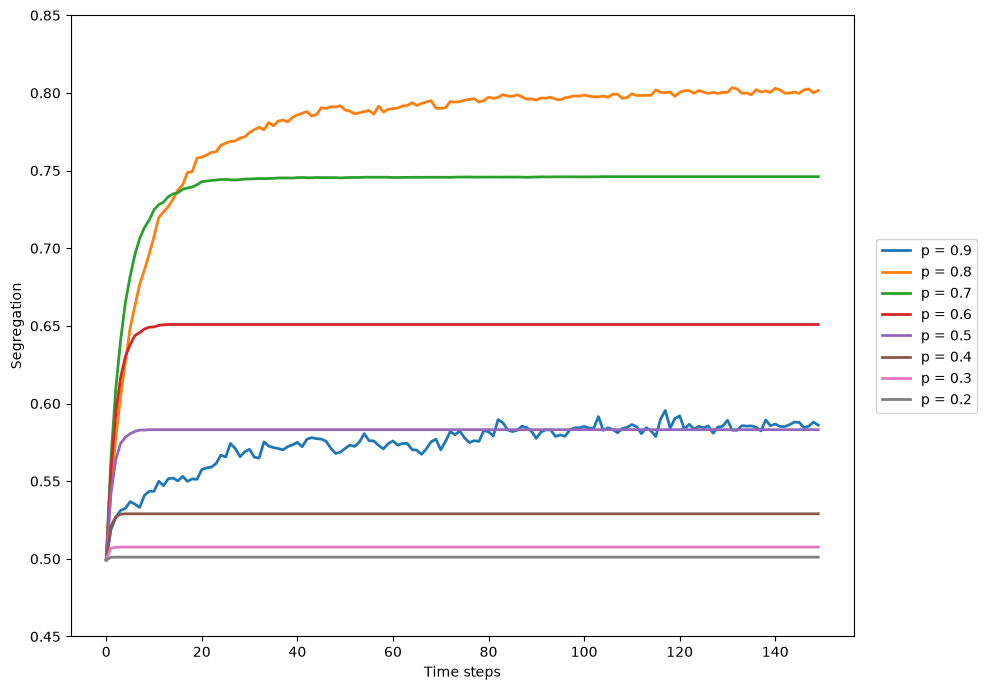

In [119]:
plt.figure(figsize=(10, 7))

for i, p in enumerate([0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2]):

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(150)]

    plt.plot(
        segs,
        label='p = %.1f' % p
    )

decorate(
    xlabel='Time steps',
    ylabel='Segregation', #Segregation 表示一个 Agent 周围的已占用邻居中，有多少比例和自己属于同一个 group，然后再对所有 Agent 取平均。
    ylim=[0.45, 0.85]
)

# 把 legend 放到图的右边外面
plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

# 图 2：p=0.2 ～ 0.7的稳定速度
这张图主要用来看模型大约需要多少timestep才能稳定。低p情况，例如p=0.2 ～ 0.4，几乎马上稳定，因为大多数Agent一开始已经满足要求。随着p增加，模型需要更多timestep才能稳定，例如 \(p=0.6\) 和 \(p=0.7\) 大约需要15–30个timestep。总体上说明：在正常范围内，满意度要求越高，系统达到稳定状态所需要的时间越长。

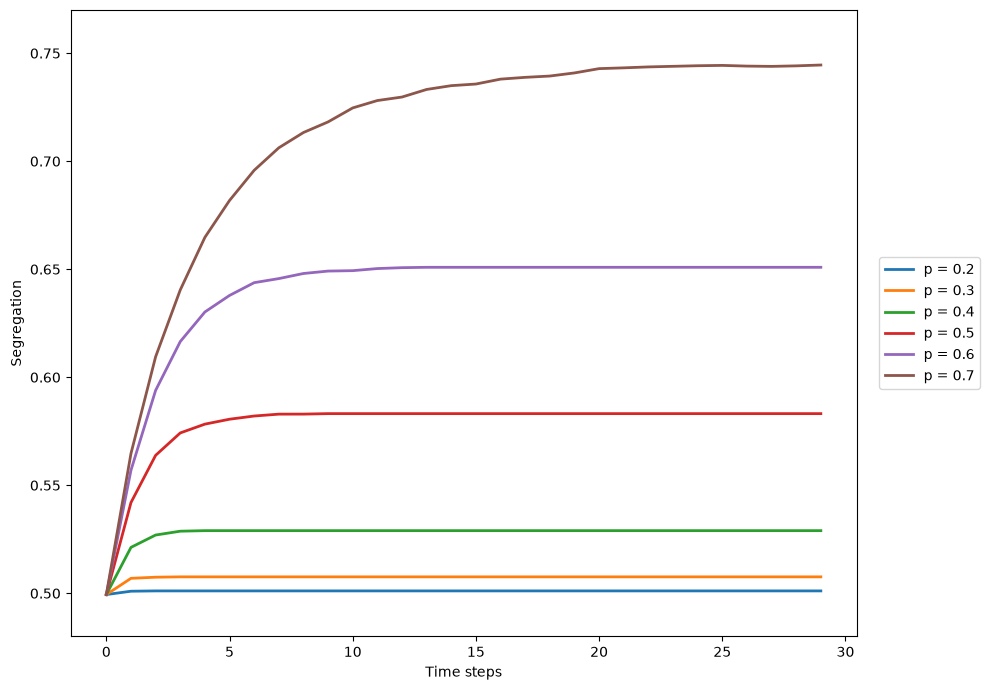

In [120]:
plt.figure(figsize=(10, 7))

for p in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(30)]

    plt.plot(segs, label='p = %.1f' % p)

plt.xlabel('Time steps')
plt.ylabel('Segregation')
plt.ylim(0.48, 0.77)

plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

# 图 3：p=0.7 ～ 0.9的高满意度区域
这张图把高p区域进一步放大。可以看到p=0.7到0.8时segregation较高，而且最后能够接近稳定；但是从大约p=0.85开始，最终segregation明显下降，同时曲线波动增加。到p=0.9时这种现象最明显。因此，高满意度要求并不一定导致更严重的segregation，反而可能使Agent长时间持续移动，导致系统难以达到equilibrium。

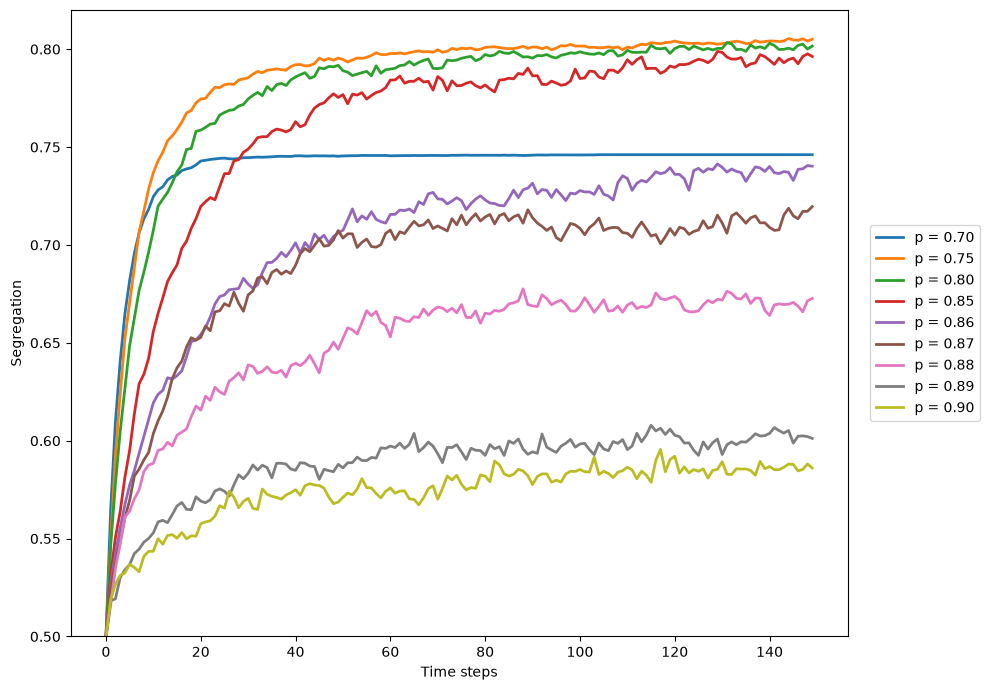

In [121]:
plt.figure(figsize=(10, 7))

for p in [0.7, 0.75, 0.8, 0.85, 0.86, 0.87, 0.88, 0.89, 0.9]:

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(150)]

    plt.plot(segs, label='p = %.2f' % p)

plt.xlabel('Time steps')
plt.ylabel('Segregation')
plt.ylim(0.50, 0.82)

plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

# 图 4：p=0.75 ～ 0.80的峰值搜索
目前可以认为，在当前模型参数下，segregation的峰值区域大约位于p=0.76 ～ 0.77。这只是当前实验得到的数值峰值，之后还可以增加random seeds来确认它是否稳定。

p = 0.75, mean segregation = 0.8065
p = 0.76, mean segregation = 0.8223
p = 0.77, mean segregation = 0.8216
p = 0.78, mean segregation = 0.8070
p = 0.79, mean segregation = 0.8086
p = 0.80, mean segregation = 0.8086

Peak p = 0.76
Maximum segregation = 0.8223425000990587


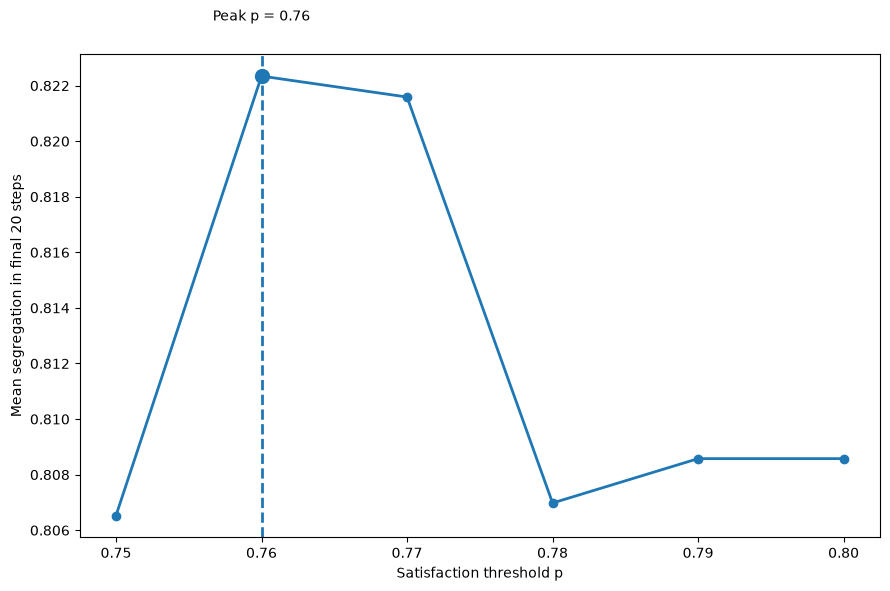

In [122]:
# Test p from 0.75 to 0.80
p_values = np.round(np.arange(0.75, 0.801, 0.01), 2)

seeds = range(5)
n_steps = 200
final_window = 20

mean_segs = []

for p in p_values:

    results = []

    for seed in seeds:

        np.random.seed(seed)

        grid = Schelling(n=100, p=p)

        segs = []

        for step in range(n_steps):
            grid.step()
            segs.append(grid.segregation())

        # Average segregation of the final 20 steps
        results.append(np.mean(segs[-final_window:]))

    # Average result from all seeds
    mean_segs.append(np.mean(results))

    print(f"p = {p:.2f}, "f"mean segregation = {np.mean(results):.4f}")

# Find the maximum
peak_index = np.argmax(mean_segs)

peak_p = p_values[peak_index]
peak_seg = mean_segs[peak_index]

print("\nPeak p =", peak_p)
print("Maximum segregation =", peak_seg)

# Plot
plt.figure(figsize=(9, 6))

plt.plot(p_values, mean_segs, marker='o', linewidth=2)

# Mark the peak
plt.scatter(peak_p, peak_seg, s=100)

plt.axvline(peak_p, linestyle='--')

plt.text(peak_p, peak_seg + 0.002, f'Peak p = {peak_p:.2f}', ha='center')

plt.xlabel('Satisfaction threshold p')
plt.ylabel('Mean segregation in final 20 steps')

plt.xticks(p_values)

plt.tight_layout()
plt.show()